In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import StratifiedShuffleSplit, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle
from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTE

import matplotlib.pyplot as plt

# Load your dataset
data = pd.read_csv('2yr_update.txt', delimiter=',')
#data1 = pd.read_excel('Michael_Model_RUN-6-7.xlsx', sheet_name='2Lines-fake_Training_data')
#data = data.append(data1)
data['TM_STAMP'] = (pd.to_datetime(data['TM_STAMP']).astype('int64') // 10**9)

data=data.dropna()


val = pd.read_csv('Q12023_update.txt', delimiter=',')
val['TM_STAMP'] = (pd.to_datetime(val['TM_STAMP']).astype('int64') // 10**9)
val=val.dropna()

C:\Users\Michael.Tetteh\AppData\Local\Temp\ipykernel_12812\4289275159.py:23: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  val = pd.read_csv('Q12023_update.txt', delimiter=',')


In [2]:
data

,Unnamed: 0,ID_PIEZO,TM_STAMP,DIGITS,AMP,REPORTABLE
0,0,392,1609459200,8679.682617,3.0000,True
1,1,392,1609462800,8679.713867,3.0000,True
2,2,392,1609466400,8679.676758,3.0000,True
3,3,392,1609470000,8679.657227,3.0000,True
4,4,392,1609473600,8679.676758,3.0000,True
...,...,...,...,...,...,...
21689773,22345305,998,1641699000,8858.663086,2.8125,True
21689774,22345306,998,1641699600,8858.708984,2.8125,True
21689775,22345307,998,1641700200,8858.706055,2.8125,True
21689776,22345308,998,1641700800,8858.711914,2.8125,True


In [3]:
val

,Unnamed: 0,ID_PIEZO,TM_STAMP,DIGITS,AMP,REPORTABLE
0,0,1109,1672534800,8584.845703,2.875000,True
1,1,1109,1672538400,8584.845703,2.875000,True
2,2,1109,1672542000,8584.852539,2.875000,True
3,3,1109,1672545600,8584.845703,2.875000,True
4,4,1101,1672531200,8789.166016,2.687500,True
...,...,...,...,...,...,...
1266439,1306056,2190,1677222000,8356.728516,2.973137,True
1266440,1306063,2219,1677218400,8463.169922,3.514184,True
1266441,1306064,2219,1677222000,8463.064453,3.522923,True
1266442,1306065,2478,1677214800,9003.515625,2.706708,True


In [4]:
# Preprocess the data
X = data[['ID_PIEZO','DIGITS','AMP']]
y = data['REPORTABLE']
X, y = shuffle(X, y, random_state=42)
X

,ID_PIEZO,DIGITS,AMP
11461843,1615,-99.000000,0.000000
2934684,1862,9008.424805,2.875000
12299486,2213,8938.800781,2.402242
15012065,1949,-99.000000,0.000000
19204425,1550,8846.372070,2.000000
...,...,...,...
14586186,2114,8929.592773,2.273884
2234489,2227,-99.000000,0.000183
13315092,273,8470.340820,3.000000
21081788,2195,8244.251953,3.016810


In [5]:
 #Standardize the features
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [6]:
X_train = X[:int(0.5*21689778 )]
X_val = X[int(0.5*21689778):int(0.70*21689778)]
X_test = X[int(0.70*21689778):]

y_train = y[:int(0.5*21689778)]
y_val = y[int(0.5*21689778):int(0.70*21689778)]
y_test = y[int(0.70*21689778):]

X_train

array([[ 2.15346080e-01, -3.80314693e-01, -2.14719979e-04],
       [ 5.23356452e-01,  7.50685037e-02, -2.14719979e-04],
       [ 9.61055402e-01,  7.15872112e-02, -2.14719979e-04],
       ...,
       [ 3.52516691e-01, -2.17550834e-02, -2.14719979e-04],
       [-6.39831648e-02,  7.42556558e-03, -2.14719979e-04],
       [-4.58036920e-01,  3.41635235e-02, -2.14719979e-04]])

In [7]:
# Standardize the features
#scaler = StandardScaler()
#X_train = scaler.fit_transform(X_train)
#X_val = scaler.transform(X_val)
#X_test = scaler.transform(X_test)

In [8]:
val_y = val['REPORTABLE'].astype('float')
val_x = val[['ID_PIEZO','DIGITS','AMP']]

val_x = scaler.transform(val_x)

In [9]:
def get_model():
    model = keras.Sequential([
         layers.Dense(256, activation="relu"),
         layers.Dense(256, activation="relu"),
         layers.Dense(1, activation="sigmoid")
    ])
    #opt = keras.optimizers.Adam(learning_rate=0.001)
    model.compile(optimizer='adam',
                  loss="binary_crossentropy",
                  metrics=["accuracy"])
    return model

model = get_model()
history_noise = model.fit(
    X_train, y_train,
    epochs = 10,
    batch_size=512,
    validation_data = (X_val, y_val))


Epoch 1/10
21182/21182 [==============================] - 128s 6ms/step - loss: 0.0233 - accuracy: 0.9948 - val_loss: 0.0177 - val_accuracy: 0.9958
Epoch 2/10
21182/21182 [==============================] - 117s 6ms/step - loss: 0.0165 - accuracy: 0.9965 - val_loss: 0.0122 - val_accuracy: 0.9972
Epoch 3/10
21182/21182 [==============================] - 118s 6ms/step - loss: 0.0109 - accuracy: 0.9976 - val_loss: 0.0089 - val_accuracy: 0.9976
Epoch 4/10
21182/21182 [==============================] - 118s 6ms/step - loss: 0.0090 - accuracy: 0.9978 - val_loss: 0.0099 - val_accuracy: 0.9977
Epoch 5/10
21182/21182 [==============================] - 119s 6ms/step - loss: 0.0081 - accuracy: 0.9980 - val_loss: 0.0094 - val_accuracy: 0.9977
Epoch 6/10
21182/21182 [==============================] - 117s 6ms/step - loss: 0.0171 - accuracy: 0.9980 - val_loss: 0.0072 - val_accuracy: 0.9985
Epoch 7/10
21182/21182 [==============================] - 117s 6ms/step - loss: 0.0071 - accuracy: 0.9983 - val_

In [10]:
history_dict = history_noise.history
history_dict.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

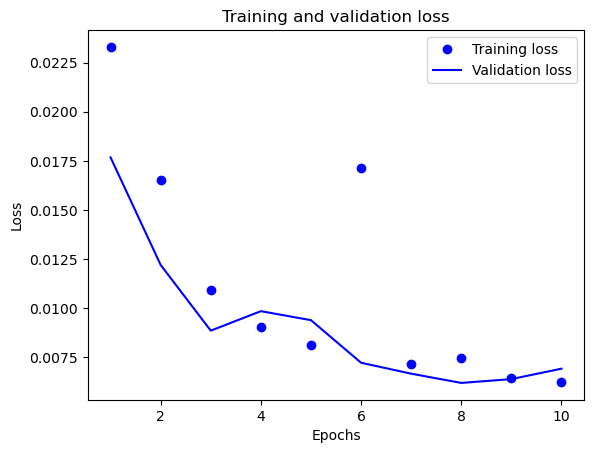

In [11]:
history_dict = history_noise.history
loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]
epochs = range(1, len(loss_values) + 1)
plt.plot(epochs, loss_values, "bo", label="Training loss")
plt.plot(epochs, val_loss_values, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

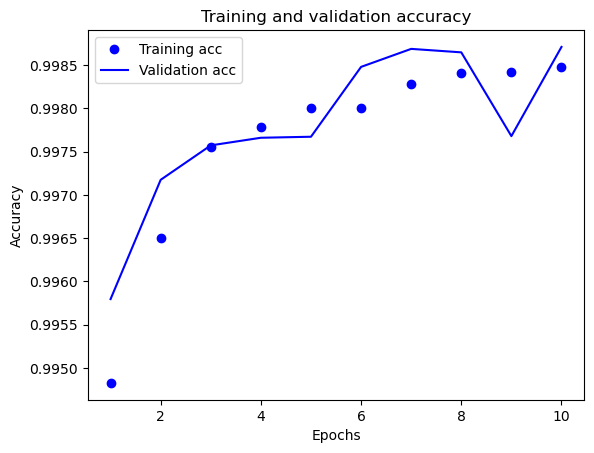

In [12]:
plt.clf()
acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]
plt.plot(epochs, acc, "bo", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [ ]:
results = model.evaluate(X_test, y_test)

In [ ]:
pred = model.predict(X_test)

In [ ]:
for i in range(len(pred)):
    if pred[i] >= 0.5:
        pred[i] = 1
    else:
        pred[i] = 0

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

In [13]:
pred_val = model.evaluate(val_x, val_y)

39577/39577 [==============================] - 64s 2ms/step - loss: 0.0728 - accuracy: 0.9966


In [14]:
pre_val= model.predict(val_x)
pre_val

39577/39577 [==============================] - 58s 1ms/step


array([[0.9999687 ],
       [0.9999687 ],
       [0.9999687 ],
       ...,
       [0.9999906 ],
       [0.99999285],
       [0.99999285]], dtype=float32)

In [15]:
for i in range(len(pre_val)):
    if pre_val[i] >= 0.5:
        pre_val[i] = 1
    else:
        pre_val[i] = 0

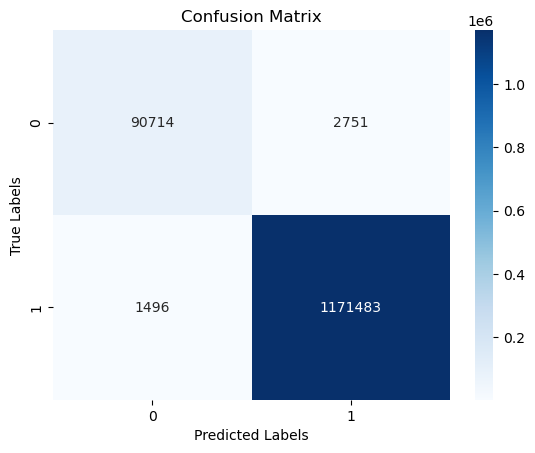

In [16]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
cm = confusion_matrix(val_y, pre_val)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

In [ ]:
# Add the predictions to the new dataset
val['PREDICTIONS'] = pre_val

val['TM_STAMP'] = pd.to_datetime(val['TM_STAMP'], unit='s')
val

In [ ]:
import pandas as pd
from sklearn.metrics import confusion_matrix

# Assuming you already have the new_data dataframe
# Step 2: Create a new column to store the comparison results
val['COMPARE'] = val['REPORTABLE'] == (val['PREDICTIONS'] == 1)

# Get unique ID_PIEZO values for predicted false and actual REPORTABLE false
predicted_false = val.loc[val['PREDICTIONS'] == 0, 'ID_PIEZO'].unique()
actual_reportable_false = val.loc[val['REPORTABLE'] == False, 'ID_PIEZO'].unique()

# Save the unique ID_PIEZO's for predicted false and actual REPORTABLE false in separate text files
with open("PIEZO_Predicted_False.txt", 'w') as f:
    for id_piezo in predicted_false:
        f.write(str(id_piezo) + '\n')

with open("Actual_Piezo_Reportable_False.txt", 'w') as f:
    for id_piezo in actual_reportable_false:
        f.write(str(id_piezo) + '\n')

# Step 4: Create a confusion matrix
y_true = val['REPORTABLE']
y_pred = val['PREDICTIONS'].apply(lambda x: x == 1)  # Convert 1's and 0's to boolean values
cm = confusion_matrix(y_true, y_pred)

# Create a labeled confusion matrix using a Pandas DataFrame
labeled_cm = pd.DataFrame(cm, index=['Actual: False', 'Actual: True'], columns=['Predicted: False', 'Predicted: True'])

print("Confusion Matrix:")
print(labeled_cm)

In [ ]:
val['REPORTABLE'] =val['REPORTABLE'].astype('float')

In [ ]:
val

In [ ]:
filtered_df = val[val['COMPARE'] == False]
filtered_df

In [ ]:
# importing os module
# Directory
import shutil
import os
directory = "ML_FIGURES"

 

dir ="C:/Temp/ML_FIGURES"
if os.path.exists(dir):
    shutil.rmtree(dir)
os.makedirs(dir)

In [ ]:
import matplotlib.pyplot as plt

val['REPORTABLE']=val['REPORTABLE']+0.1

# Filter the dataframe

filtered_df = val[val['COMPARE'] == False]

 

# Get the unique 'ID_PIEZO' values

unique_ids = filtered_df['ID_PIEZO'].unique()



# Plot data for each unique 'ID_PIEZO'

for id in unique_ids:

    # Filter dataframe for the current 'ID_PIEZO'

    df_id = val[val['ID_PIEZO'] == id]
 

    # Create a new figure and two subplots, sharing x-axis

    fig, ax1 = plt.subplots()

 

    # First subplot for 'X' values

    ax1.plot(df_id['TM_STAMP'], df_id['DIGITS'], 'bo', markersize=3)

    ax1.set_xlabel('Time')
    plt.xticks(rotation=90)

    # Make the y-axis label and line color blue to match the line color.

    ax1.set_ylabel('DIGITS', color='b')

    ax1.tick_params('y', colors='b')

 
    # Second subplot for 'Y' values, sharing the same x-axis

    ax2 = ax1.twinx()

    ax2.plot(df_id['TM_STAMP'], df_id['AMP'], 'ro', markersize=3)

    # Make the y-axis label and line color red to match the line color.

    ax2.set_ylabel('AMPS', color='r')

    ax2.tick_params('y', colors='r')
    
    # Create a third axis sharing the same x-axis
    ax3 = ax1.twinx()

    # Offset the third axis
    ax3.spines['right'].set_position(('outward', 60))

    # Plot data on the third axis
    ax3.plot(df_id['TM_STAMP'],df_id['PREDICTIONS'],'gx', markersize=2, label='predicted_labels')
    ax3.plot(df_id['TM_STAMP'],df_id['REPORTABLE'],'yx', markersize=3, label='Actual_labels')
    ax3.set_ylabel('REPORTABLES', color='black')
    ax3.tick_params('y', colors='black')
    
    # Add a legend
    lines = ax3.get_lines()
    ax3.legend(lines, [line.get_label() for line in lines])
    # Add a title to the plot

    plt.title(f"Data for ID_PIEZO = {id}")


    fig.tight_layout()  # This ensures the right y-label is not cut off
    


    plt.show()
    #
    fig.savefig('C:\Temp\ML_FIGURES\{0}.png'.format(id), bbox_inches='tight',dpi=300)